In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [93]:
df = pd.read_csv("loan_approval_data.csv")

In [94]:
df.head()
df.info()
df.isnull().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [95]:
categorical_coln=df.select_dtypes(include=["object"]).columns
numerical_coln=df.select_dtypes(include=["float64"]).columns

In [96]:
categorical_coln

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [97]:
numerical_coln

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [98]:
from sklearn.impute import SimpleImputer
num_imp=SimpleImputer(strategy="mean")
df[numerical_coln]=num_imp.fit_transform(df[numerical_coln])

In [99]:
cat_imp=SimpleImputer(strategy="most_frequent")
df[categorical_coln]=cat_imp.fit_transform(df[categorical_coln])

Text(0.5, 1.0, 'Is Loan Approved or Not ?')

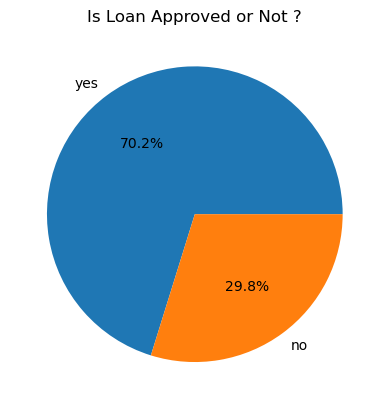

In [100]:
classes_count=df["Loan_Approved"].value_counts()
plt.pie(classes_count,labels=["yes","no"],autopct="%1.1f%%")
plt.title("Is Loan Approved or Not ?")


[Text(0, 0, '515'), Text(0, 0, '213'), Text(0, 0, '182'), Text(0, 0, '90')]

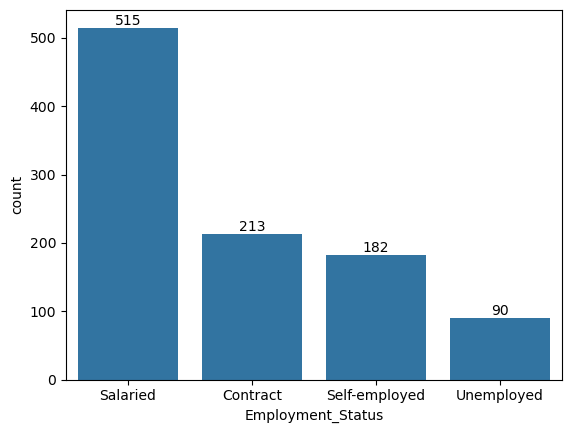

In [101]:
emp_count=df["Employment_Status"].value_counts()
a=sns.barplot(emp_count)
a.bar_label(a.containers[0])

Text(0.5, 1.0, 'Marital_Status?')

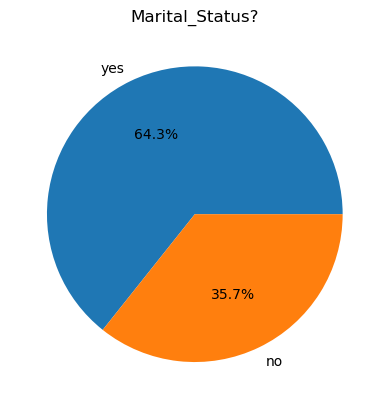

In [102]:
classes_count=df["Marital_Status"].value_counts()
plt.pie(classes_count,labels=["yes","no"],autopct="%1.1f%%")
plt.title("Marital_Status?")

In [103]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


[Text(0, 0, '252'),
 Text(0, 0, '199'),
 Text(0, 0, '190'),
 Text(0, 0, '181'),
 Text(0, 0, '178')]

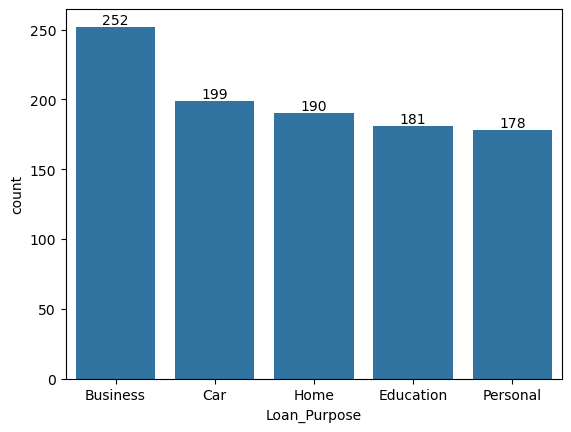

In [104]:
emp_count=df["Loan_Purpose"].value_counts()
a=sns.barplot(emp_count)
a.bar_label(a.containers[0])

[Text(0, 0, '517'), Text(0, 0, '294'), Text(0, 0, '189')]

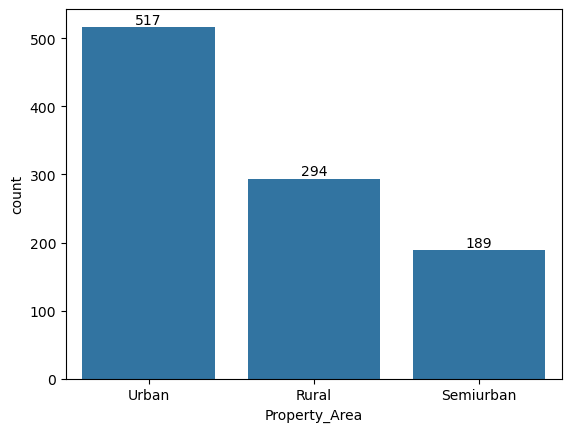

In [105]:
emp_count=df["Property_Area"].value_counts()
a=sns.barplot(emp_count)
a.bar_label(a.containers[0])

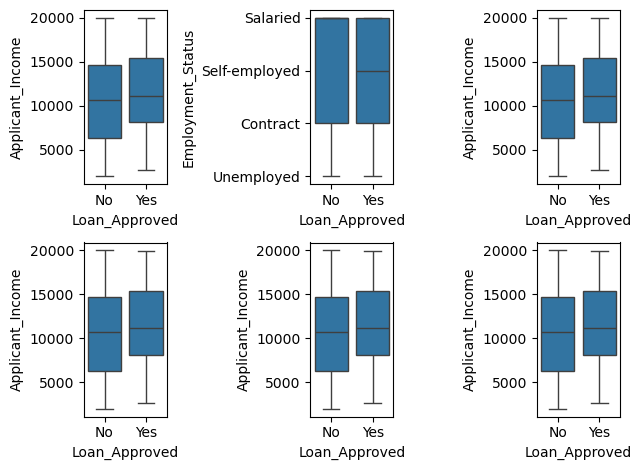

In [106]:
fig,ax=plt.subplots(2,3)
sns.boxplot(ax=ax[0,0],data=df,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=ax[0,1],data=df,x="Loan_Approved",y="Employment_Status")
sns.boxplot(ax=ax[1,0],data=df,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=ax[1,1],data=df,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=ax[1,2],data=df,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=ax[0,2],data=df,x="Loan_Approved",y="Applicant_Income")
plt.tight_layout()

In [107]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le=LabelEncoder()
df["Education_Level"]=le.fit_transform(df["Education_Level"])
df["Loan_Approved"]=le.fit_transform(df["Loan_Approved"])
cols=["Employer_Category","Gender","Property_Area","Marital_Status","Loan_Purpose","Property_Area","Employment_Status"]

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        1000 non-null   float64
 1   Applicant_Income    1000 non-null   float64
 2   Coapplicant_Income  1000 non-null   float64
 3   Employment_Status   1000 non-null   object 
 4   Age                 1000 non-null   float64
 5   Marital_Status      1000 non-null   object 
 6   Dependents          1000 non-null   float64
 7   Credit_Score        1000 non-null   float64
 8   Existing_Loans      1000 non-null   float64
 9   DTI_Ratio           1000 non-null   float64
 10  Savings             1000 non-null   float64
 11  Collateral_Value    1000 non-null   float64
 12  Loan_Amount         1000 non-null   float64
 13  Loan_Term           1000 non-null   float64
 14  Loan_Purpose        1000 non-null   object 
 15  Property_Area       1000 non-null   object 
 16  Educati

In [109]:
cols=["Employer_Category","Gender","Property_Area","Marital_Status","Loan_Purpose","Property_Area","Employment_Status"]
on=OneHotEncoder(drop="first",sparse_output=False,handle_unknown="ignore")
encode=on.fit_transform(df[cols])
encode_df=pd.DataFrame(encode,columns=on.get_feature_names_out(cols),index=df.index)

In [110]:
df=pd.concat([df.drop(columns=cols),encode_df],axis=1)

In [112]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed
0,1.0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
1,2.0,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,3.0,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
3,4.0,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,5.0,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


<Axes: >

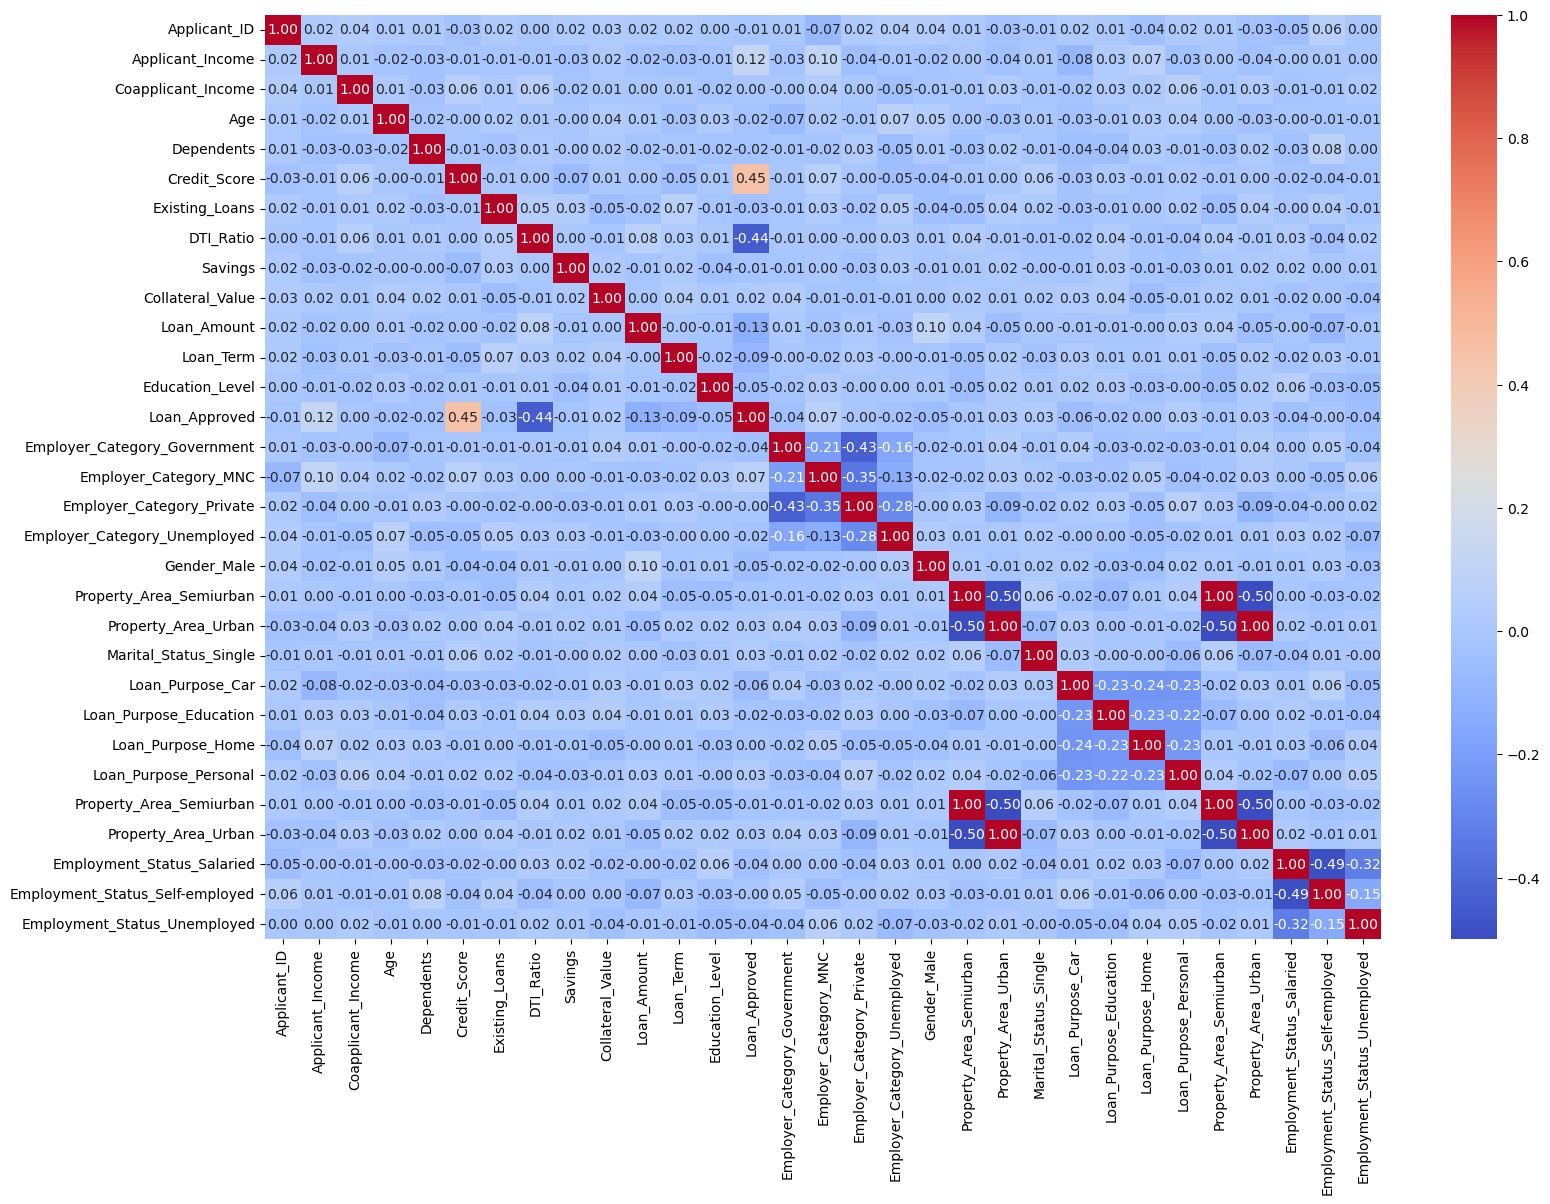

In [123]:
num_cols=df.select_dtypes(include="number")
coor_matrix=num_cols.corr()
plt.figure(figsize=(18,12))
sns.heatmap(
    coor_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
    
)

In [118]:
num_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Applicant_ID                      -0.011167
Property_Area_Semiurban           -0.012967
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government    

In [124]:
X=df.drop("Loan_Approved",axis=1)
y=df["Loan_Approved"]

In [128]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [134]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [144]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,precision_score,accuracy_score,recall_score,f1_score
log_reg=LogisticRegression()
log_reg.fit(X_train_scaled,y_train)
y_pred=log_reg.predict(X_test_scaled)
print("LogisticRegression Model")
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

LogisticRegression Model
confusion_matrix: [[126  13]
 [ 13  48]]
precision_score: 0.7868852459016393
accuracy_score: 0.87
recall_score: 0.7868852459016393
f1_score: 0.7868852459016393


In [151]:
from sklearn.neighbors import KNeighborsClassifier

knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)
y_pred=knn.predict(X_test_scaled)
print("KNeighborsClassifier Model")
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

KNeighborsClassifier Model
confusion_matrix: [[117  22]
 [ 32  29]]
precision_score: 0.5686274509803921
accuracy_score: 0.73
recall_score: 0.47540983606557374
f1_score: 0.5178571428571429


In [154]:
from sklearn.naive_bayes import GaussianNB

naive_bayes=GaussianNB()
naive_bayes.fit(X_train_scaled,y_train)
y_pred=naive_bayes.predict(X_test_scaled)
print("naive_bayes Model")
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

naive_bayes Model
confusion_matrix: [[129  10]
 [ 19  42]]
precision_score: 0.8076923076923077
accuracy_score: 0.855
recall_score: 0.6885245901639344
f1_score: 0.7433628318584071


In [158]:
df["DTI_Ratio_sq"]=df["DTI_Ratio"] ** 2
df["Credit_Score_sq"]=df["Credit_Score"]**2
df["Applicant_Income_log"]=np.log1p(df["Applicant_Income"])

X=df.drop(columns=["Loan_Approved","DTI_Ratio","Credit_Score","Applicant_Income"])
y=df["Loan_Approved"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [162]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,precision_score,accuracy_score,recall_score,f1_score
log_reg=LogisticRegression()
log_reg.fit(X_train_scaled,y_train)
y_pred=log_reg.predict(X_test_scaled)
print("LogisticRegression Model")
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

LogisticRegression Model
confusion_matrix: [[125  14]
 [ 12  49]]
precision_score: 0.7777777777777778
accuracy_score: 0.87
recall_score: 0.8032786885245902
f1_score: 0.7903225806451613


In [163]:
from sklearn.naive_bayes import GaussianNB

naive_bayes=GaussianNB()
naive_bayes.fit(X_train_scaled,y_train)
y_pred=naive_bayes.predict(X_test_scaled)
print("naive_bayes Model")
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

naive_bayes Model
confusion_matrix: [[130   9]
 [ 18  43]]
precision_score: 0.8269230769230769
accuracy_score: 0.865
recall_score: 0.7049180327868853
f1_score: 0.7610619469026548
